In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ANALYSING THE DATA

In [92]:
Customer_data=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [93]:
Customer_data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [94]:
Customer_data.shape

(7043, 21)

In [95]:
for col in Customer_data.columns:
 if(Customer_data[col].isnull().any()):
  print(col)
  #Hence our data do not consist of any missing value for any column but still there can be some missing values 

In [96]:
Customer_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [97]:
Customer_data["TotalCharges"]=pd.to_numeric(Customer_data["TotalCharges"], errors="coerce")
Customer_data["TotalCharges"].isnull().sum()

np.int64(11)

Till now we found that only column containing missing values is TotaCharges and it has 11 missing values further there are 17 columns with string data type but customer id is identifier so 16 categorical columns

In [98]:
Customer_data["Churn"].value_counts()
#approx 5200 customers did not churn and 1900 did churn the companyy

Churn
No     5174
Yes    1869
Name: count, dtype: int64

DATA VISUALISATION

<function matplotlib.pyplot.show(close=None, block=None)>

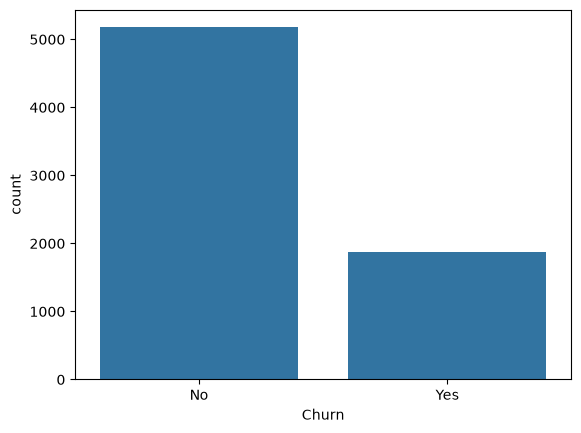

In [99]:
sns.countplot(x="Churn",data=Customer_data)
plt.show

Text(0.5, 1.0, 'Relationship between monthly charges and churn')

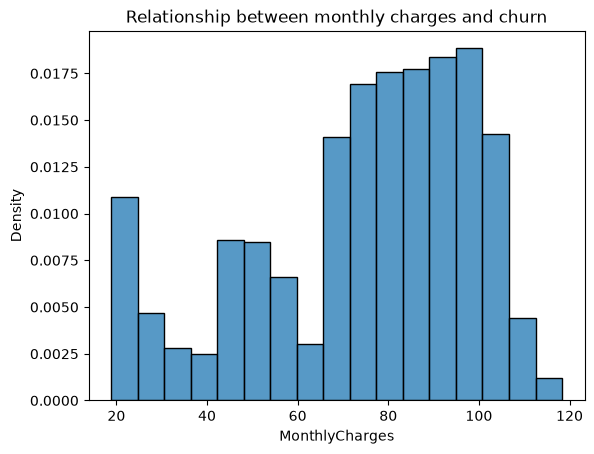

In [100]:
sns.histplot(x="MonthlyCharges",data=Customer_data[Customer_data["Churn"] == "Yes"],stat="density")
plt.show
plt.title("Relationship between monthly charges and churn")

<function matplotlib.pyplot.show(close=None, block=None)>

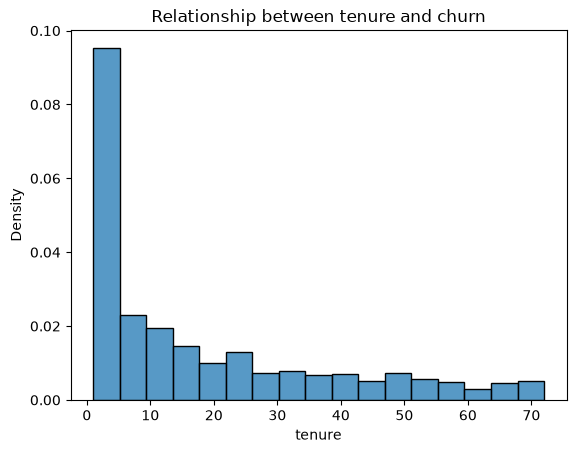

In [101]:
sns.histplot(x="tenure",data=Customer_data[Customer_data["Churn"]=="Yes"],stat="density")
plt.title("Relationship between tenure and churn")
plt.show
#hence we figure out that the customers who churned mainly were using tghe service of company of over 5 to 10 months

<function matplotlib.pyplot.show(close=None, block=None)>

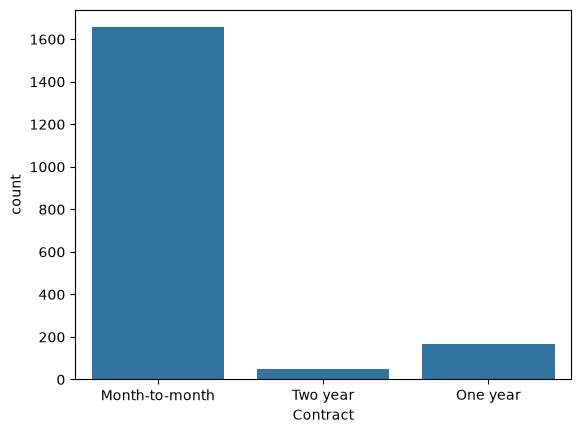

In [102]:
sns.countplot(x="Contract",data=Customer_data[Customer_data["Churn"]=="Yes"])
plt.show
#mainly customers with month to month contract have churned

<function matplotlib.pyplot.show(close=None, block=None)>

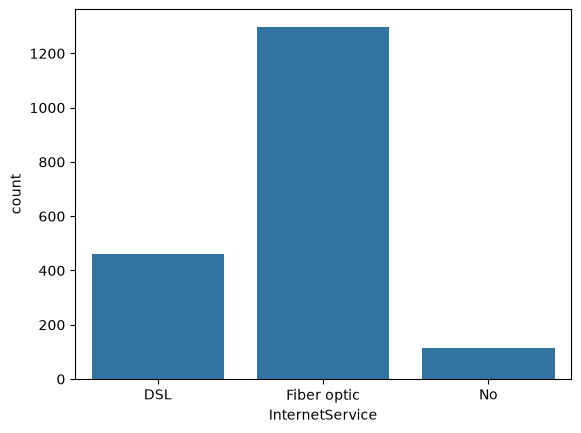

In [103]:
sns.countplot(x="InternetService",data=Customer_data[Customer_data["Churn"]=="Yes"])
plt.show
#mainly customers with fibre optic internet service have churned 

<Axes: xlabel='PhoneService', ylabel='Count'>

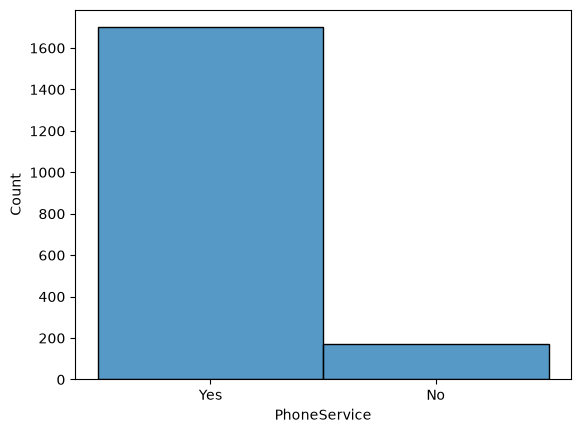

In [104]:
sns.histplot(x="PhoneService",data=Customer_data[Customer_data["Churn"]=="Yes"])

In [105]:
Customer_data.groupby("Contract")["Churn"].value_counts(normalize=True)

Contract        Churn
Month-to-month  No       0.572903
                Yes      0.427097
One year        No       0.887305
                Yes      0.112695
Two year        No       0.971681
                Yes      0.028319
Name: proportion, dtype: float64

In [106]:
Customer_data.groupby("InternetService")["Churn"].value_counts(normalize=True)

InternetService  Churn
DSL              No       0.810409
                 Yes      0.189591
Fiber optic      No       0.581072
                 Yes      0.418928
No               No       0.925950
                 Yes      0.074050
Name: proportion, dtype: float64

Data visulaisation Observations:

Month-to-month contract customers have a higher churn rate (~42%).

Fiber optic internet customers have a higher churn rate (~41%).

Many churned customers have monthly charges between 70–110 Rs

Many churned customers have a tenure of around 5–10 months.

Around 1,600 out of 1900 churned customers had phone service.

DATA PREPOCESSING

In [107]:
Customer_data[Customer_data["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Since the customers with NaN total charges have 0 tenure it basically signifies that they have not been charged yet and hence we can replace the null values with 0 in total charges column for these customers

In [108]:
Customer_data["TotalCharges"]=Customer_data["TotalCharges"].fillna(0)
data=Customer_data.copy()

In [109]:
data=data.drop("customerID",axis=1)
X=data.drop("Churn",axis=1)
Y=data["Churn"]

In [110]:
from sklearn.model_selection import train_test_split
X_train, X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.25,random_state=51,stratify=Y)

In [111]:
from sklearn.preprocessing import OneHotEncoder
categorical_cols = [cols for cols in X.columns
                    if X[cols].dtype == "str"]
encoder = OneHotEncoder(sparse_output=False)

pre_X = encoder.fit_transform(X_train[categorical_cols])
pre_X_test = encoder.transform(X_test[categorical_cols])
encoded_cols = encoder.get_feature_names_out(categorical_cols)
pre_X = pd.DataFrame(
    pre_X,
    columns=encoded_cols,
    index=X_train.index
)

pre_X_test = pd.DataFrame(
    pre_X_test,
    columns=encoded_cols,
    index=X_test.index
)

X_train_1 = X_train.copy()
X_test_1 = X_test.copy()

X_train_1 = X_train_1.drop(categorical_cols, axis=1)
X_test_1 = X_test_1.drop(categorical_cols, axis=1)

X_train_encoded = pd.concat([X_train_1, pre_X], axis=1)
X_test_encoded = pd.concat([X_test_1, pre_X_test], axis=1)
Y_train = Y_train.map({"No": 0, "Yes": 1})
Y_test = Y_test.map({"No": 0, "Yes": 1})

In [112]:
X_train_encoded.head(5)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
6561,0,9,73.80,704.30,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1417,1,18,49.85,865.75,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
6550,0,21,106.10,2249.95,0.0,1.0,0.0,1.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4275,0,1,25.75,25.75,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
6532,1,18,20.35,369.60,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


Model 1

In [113]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=2000,class_weight="balanced")
model.fit(X_train_encoded,Y_train)
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
y_pred=model.predict(X_test_encoded)
print("Accuracy is = ",accuracy_score(Y_test,y_pred))
print("classification report = ",classification_report(Y_test,y_pred))
print("confusion matrix = ",confusion_matrix(Y_test,y_pred))

Accuracy is =  0.760931289040318
classification report =                precision    recall  f1-score   support

           0       0.92      0.74      0.82      1294
           1       0.53      0.82      0.65       467

    accuracy                           0.76      1761
   macro avg       0.73      0.78      0.73      1761
weighted avg       0.82      0.76      0.77      1761

confusion matrix =  [[955 339]
 [ 82 385]]


Hence since the churn recall that is the percentage of churned customers identified by our model is close to 82% which is a good sign 

Model 2

In [114]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
model=DecisionTreeClassifier(max_depth=8,random_state=50,max_leaf_nodes=20,min_samples_leaf=40,class_weight="balanced")
model.fit(X_train_encoded,Y_train)
y_pred=model.predict(X_test_encoded)
print("accuracy =",accuracy_score(Y_test,y_pred))
print("classification_report =",classification_report(Y_test,y_pred))
print("confusion_matrix = ",confusion_matrix(Y_test,y_pred))

accuracy = 0.7677455990914254
classification_report =               precision    recall  f1-score   support

           0       0.89      0.78      0.83      1294
           1       0.55      0.72      0.62       467

    accuracy                           0.77      1761
   macro avg       0.72      0.75      0.73      1761
weighted avg       0.80      0.77      0.78      1761

confusion_matrix =  [[1015  279]
 [ 130  337]]


This model 2 is a tiny better accuracy than model 1 but significantly lower churn recall which is the most importat feature of our model

Model 3

In [115]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
model=RandomForestClassifier(n_estimators=100,max_depth=10,max_leaf_nodes=20,min_samples_leaf=20,class_weight="balanced",random_state=50)
model.fit(X_train_encoded,Y_train)
y_pred=model.predict(X_test_encoded)
print("Accuracy is = ",accuracy_score(Y_test,y_pred))
print("classification_report is ",classification_report(Y_test,y_pred))
print("confusion matrix ",confusion_matrix(Y_test,y_pred))

Accuracy is =  0.7563884156729132
classification_report is                precision    recall  f1-score   support

           0       0.90      0.75      0.82      1294
           1       0.53      0.78      0.63       467

    accuracy                           0.76      1761
   macro avg       0.72      0.76      0.72      1761
weighted avg       0.80      0.76      0.77      1761

confusion matrix  [[967 327]
 [102 365]]


Hence comparing all three models :
Model 1 (LogisticRegression) is the most suitable for the work as it identifies akmost 82 percent of churn customers with the precision of 53 percent and has an overall accuracy of 76 percent

Threshold comparision for our final model

In [116]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score,recall_score,f1_score
final_model=LogisticRegression(max_iter=2000,class_weight="balanced")
final_model.fit(X_train_encoded,Y_train)
y_pred=final_model.predict_proba(X_test_encoded)[: ,1]
for threshold in[0.3,0.4,0.5,0.6]:
    y_pred_f=(y_pred>=threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_score(Y_test, y_pred_f):.3f} | "
        f"Recall: {recall_score(Y_test, y_pred_f):.3f} | "
        f"F1: {f1_score(Y_test, y_pred_f):.3f}"
    )

Threshold: 0.30 | Precision: 0.430 | Recall: 0.927 | F1: 0.587
Threshold: 0.40 | Precision: 0.471 | Recall: 0.872 | F1: 0.612
Threshold: 0.50 | Precision: 0.532 | Recall: 0.824 | F1: 0.647
Threshold: 0.60 | Precision: 0.570 | Recall: 0.698 | F1: 0.628


Hence if we want to churn the maximum number of customers we will use threshold of 0.3 or else if we want a overall better precision and churn recall 0.5 is the option for threshold

CROSS_VALIDATION OF THE MODEL

In [117]:
from sklearn.model_selection import StratifiedKFold,cross_val_score
from sklearn.linear_model import LogisticRegression

final_model = LogisticRegression(
    max_iter=3000,
    class_weight="balanced"
)
skf=StratifiedKFold(n_splits=5,random_state=50,shuffle=True)

scores = cross_val_score(
    final_model,
    X_train_encoded,
    Y_train,
    cv=skf,
    scoring="f1"
)

print("F1 scores:", scores)
print("Mean F1 score:", scores.mean())

F1 scores: [0.65174825 0.61983471 0.6115007  0.61517241 0.60366714]
Mean F1 score: 0.6203846428719683


So cross validation of our model gives and average f1 score of 62 which is close to the f1 score we got in the testing set which was 64 hence our model is not overfitted

Final model

In [118]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

final_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

final_model.fit(X_train_encoded, Y_train)

y_pred_final = final_model.predict(X_test_encoded)

print("Accuracy:", accuracy_score(Y_test, y_pred_final))
print("\nClassification Report:")
print(classification_report(Y_test, y_pred_final))
print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, y_pred_final))

Accuracy: 0.760931289040318

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.74      0.82      1294
           1       0.53      0.82      0.65       467

    accuracy                           0.76      1761
   macro avg       0.73      0.78      0.73      1761
weighted avg       0.82      0.76      0.77      1761


Confusion Matrix:
[[955 339]
 [ 82 385]]


Conclusion:
The goal of this project was to predict customer churn using supervised machine learning. I explored the dataset, cleaned missing values, encoded categorical features, and compared Logistic Regression, Decision Tree, and Random Forest models. Class weighting helped improve the identification of churners. My balanced Logistic Regression model achieved approximately 76.09% accuracy and 82.44% recall for the churn class. This means the model identified a large proportion of customers who actually churned, although it also produced false positives. Further improvements could include threshold tuning on validation data and testing additional features.